In [31]:
import os
import numpy as np
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [14]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"
input_dir = "../1_inputs/sqY2H"

In [15]:
all_variants_df = pd.read_csv(f"{input_dir}/all_gene_alleles_profiled_by_any_assay.csv")
all_variants_df_ppi = all_variants_df[~all_variants_df["ppi_score_final_euclidean"].isna()]
all_variants_df_ppi

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit
0,LITAF,LITAF_Gly112Ser,ENSG00000189067,NC_000016.10:11553576:C:T,52920,2677.0,334G>A,Gly112Ser,1_Pathogenic,6.840600e-07,...,0.083333,<10,70-90,NaN,NaN,NaN,0.899325,False,0.223933,False
4,THAP1,THAP1_Gly9Cys,ENSG00000131931,NC_000008.11:42843070:C:A,1668,214082.0,25G>T,Gly9Cys,1_Pathogenic,NaN,...,0.821429,10-90,70-90,NaN,NaN,NaN,0.728205,False,0.181243,False
7,GALE,GALE_Arg239Trp,ENSG00000117308,NC_000001.11:23796777:G:A,2767,214360.0,715C>T,Arg239Trp,1_Pathogenic,8.230060e-06,...,0.112903,10-90,>90,0.113185,N,Increase,0.787624,False,0.106609,False
13,PCCA,PCCA_Ile450Val,ENSG00000175198,NC_000013.11:100309902:A:G,888,200364.0,1348A>G,Ile450Val,2_Benign,4.779260e-02,...,0.017751,<10,>90,NaN,NaN,NaN,NaN,NaN,0.373866,False
14,IER3IP1,IER3IP1_Val21Gly,ENSG00000134049,NC_000018.10:47176216:A:C,6408,215945.0,62T>G,Val21Gly,4_VUS,2.749860e-06,...,0.281690,10-90,50-70,NaN,NaN,NaN,NaN,NaN,0.251640,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1428,KRT6A,KRT6A_Glu472Lys,ENSG00000205420,NC_000012.12:52488338:C:T,4870,215286.0,1414G>A,Glu472Lys,1_Pathogenic,NaN,...,0.520619,10-90,50-70,0.282414,N,Increase,0.836835,False,0.199536,False
1429,TPM1,TPM1_Asp175Asn,ENSG00000140416,NC_000015.10:63060899:G:A,4723,8952.0,523G>A,Asp175Asn,1_Pathogenic,6.840680e-06,...,0.515337,10-90,>90,0.964807,Uncertain,Increase,NaN,NaN,0.242798,False
1430,SMAD3,SMAD3_Met255Arg,ENSG00000166949,NC_000015.10:67181346:T:G,11805,2144.0,764T>G,Met255Arg,4_VUS,NaN,...,0.010638,<10,>90,-5.913824,Y,Decrease,0.953229,True,0.407091,False
1437,AGXT,AGXT_Pro319Leu,ENSG00000172482,NC_000002.12:240878035:C:T,70497,3878.0,956C>T,Pro319Leu,1_Pathogenic,NaN,...,0.125000,10-90,>90,-5.645154,Y,Decrease,0.741186,False,0.436285,False


In [16]:
scores = pl.read_csv(f"{sqy2h_outputs_dir}/6_variants_perturbation_scores_automated_annotated.csv")

In [17]:
scores_pd = scores.to_pandas()
scores_pd

,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,...,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,ppi_hit
0,291.335890,291.335890,0.106659,291.335890,1.119393,1.119393,0.162716,0.162716,NaN,1,...,TTR_Ile88Leu,8999,202999,TTR,Ile88Leu,ENSG00000118271,1_Pathogenic,1.094520e-05,2.0,False
1,7433.634245,7433.634245,0.886822,7433.634245,8.835638,8.835638,3.143334,3.143334,NaN,1,...,NCF2_Gly44Arg,3727,214871,NCF2,Gly44Arg,ENSG00000116701,5_Others,NaN,NaN,True
2,5237.574029,-5237.574029,-1.786488,5237.574029,0.358875,0.358875,-1.478448,1.478448,NaN,1,...,GATA2_Cys373Arg,7465,216383,GATA2,Cys373Arg,ENSG00000179348,1_Pathogenic,NaN,2.0,True
3,3156.668069,3156.668069,0.743425,3156.668069,3.897492,3.897492,1.962546,1.962546,NaN,1,...,AP2S1_Arg15His,4983,215316,AP2S1,Arg15His,ENSG00000042753,1_Pathogenic,2.052150e-06,2.0,False
4,6964.535265,5036.682463,0.653152,5036.682463,2.883107,2.883107,1.527624,1.527624,NaN,3,...,KRT6A_Ile462Asn,4870,215289,KRT6A,Ile462Asn,ENSG00000205420,1_Pathogenic,NaN,2.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,7029.011714,4297.695528,0.469609,4297.695528,1.885402,1.885402,0.914872,0.914872,NaN,3,...,NMNAT1_Asn273Asp,7675,202587,NMNAT1,Asn273Asp,ENSG00000173614,1_Pathogenic,6.851610e-07,NaN,False
471,2561.049763,2561.049763,0.305530,2561.049763,1.439946,1.439946,0.526015,0.526015,NaN,1,...,NCF2_Asp108Val,3727,214873,NCF2,Asp108Val,ENSG00000116701,4_VUS,NaN,1.0,False
472,9694.763420,6834.451679,0.877106,6834.451679,8.137079,8.137079,3.024511,3.024511,NaN,8,...,KCTD7_Arg94Trp,70368,205542,KCTD7,Arg94Trp,ENSG00000243335,1_Pathogenic,8.892720e-06,2.0,False
473,1743.384420,-1743.384420,-0.638256,1743.384420,0.610405,0.610405,-0.712161,0.712161,NaN,1,...,TTR_Phe53Ile,8999,202979,TTR,Phe53Ile,ENSG00000118271,1_Pathogenic,NaN,NaN,False


In [18]:
for var in scores_pd.allele_0:
    if var not in all_variants_df_ppi["gene_variant"].values:
        print(var)

ACSF3_Arg471Trp
PKP2_Phe424Ser
ACSF3_Pro243Leu
ACSF3_Thr358Ile
IMPDH1_Val317Ile
MLH1_Ile36Asn
NEUROG3_Arg107Ser
GSS_Arg283Cys
LITAF_Thr115Asn
AGXT_Gly156Arg
ACSF3_Glu359Lys


In [19]:
# Select the columns we want to merge
metrics_to_add = scores_pd[['allele_0', 'max_perturbation_fold', 'max_perturbation', 
                           'max_perturbation_abs', 'max_perturbation_fold_abs', 'max_log2_fold_change']]

# Rename the key column to match
metrics_to_add = metrics_to_add.rename(columns={'allele_0': 'gene_variant'})

# Merge with all_variants_df_ppi
all_variants_df_ppi = all_variants_df_ppi.merge(metrics_to_add, on='gene_variant', how='left')

all_variants_df_ppi

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change
0,LITAF,LITAF_Gly112Ser,ENSG00000189067,NC_000016.10:11553576:C:T,52920,2677.0,334G>A,Gly112Ser,1_Pathogenic,6.840600e-07,...,NaN,0.899325,False,0.223933,False,1.784181,2457.776872,2457.776872,1.784181,0.835262
1,THAP1,THAP1_Gly9Cys,ENSG00000131931,NC_000008.11:42843070:C:A,1668,214082.0,25G>T,Gly9Cys,1_Pathogenic,NaN,...,NaN,0.728205,False,0.181243,False,0.954075,-349.390844,349.390844,0.954075,-0.067825
2,GALE,GALE_Arg239Trp,ENSG00000117308,NC_000001.11:23796777:G:A,2767,214360.0,715C>T,Arg239Trp,1_Pathogenic,8.230060e-06,...,Increase,0.787624,False,0.106609,False,0.797119,-1014.717656,1014.717656,0.797119,-0.327133
3,PCCA,PCCA_Ile450Val,ENSG00000175198,NC_000013.11:100309902:A:G,888,200364.0,1348A>G,Ile450Val,2_Benign,4.779260e-02,...,NaN,NaN,NaN,0.373866,False,1.740297,3558.513862,3558.513862,1.740297,0.799334
4,IER3IP1,IER3IP1_Val21Gly,ENSG00000134049,NC_000018.10:47176216:A:C,6408,215945.0,62T>G,Val21Gly,4_VUS,2.749860e-06,...,NaN,NaN,NaN,0.251640,False,2.534152,3021.938655,3021.938655,2.534152,1.341503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,KRT6A,KRT6A_Glu472Lys,ENSG00000205420,NC_000012.12:52488338:C:T,4870,215286.0,1414G>A,Glu472Lys,1_Pathogenic,NaN,...,Increase,0.836835,False,0.199536,False,1.460900,2282.988308,2282.988308,1.460900,0.546857
460,TPM1,TPM1_Asp175Asn,ENSG00000140416,NC_000015.10:63060899:G:A,4723,8952.0,523G>A,Asp175Asn,1_Pathogenic,6.840680e-06,...,Increase,NaN,NaN,0.242798,False,1.076935,620.684955,620.684955,1.076935,0.106931
461,SMAD3,SMAD3_Met255Arg,ENSG00000166949,NC_000015.10:67181346:T:G,11805,2144.0,764T>G,Met255Arg,4_VUS,NaN,...,Decrease,0.953229,True,0.407091,False,6.867155,4694.360995,4694.360995,6.867155,2.779713
462,AGXT,AGXT_Pro319Leu,ENSG00000172482,NC_000002.12:240878035:C:T,70497,3878.0,956C>T,Pro319Leu,1_Pathogenic,NaN,...,Decrease,0.741186,False,0.436285,False,3.988370,4152.627593,4152.627593,3.988370,1.995799


In [20]:
all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi)
all_variants_df_ppi_pl

symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,StarStatus,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change
str,str,str,str,i64,f64,str,str,str,f64,f64,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,f64,bool,f64,bool,f64,f64,f64,f64,f64
"""LITAF""","""LITAF_Gly112Ser""","""ENSG00000189067""","""NC_000016.10:11553576:C:T""",52920,2677.0,"""334G>A""","""Gly112Ser""","""1_Pathogenic""",6.8406e-7,2.0,""".""","""0.81648""",""".""","""-10.652""","""0.77788""","""D""",87.33,0.083333,"""<10""","""70-90""",null,null,null,0.899325,false,0.223933,false,1.784181,2457.776872,2457.776872,1.784181,0.835262
"""THAP1""","""THAP1_Gly9Cys""","""ENSG00000131931""","""NC_000008.11:42843070:C:A""",1668,214082.0,"""25G>T""","""Gly9Cys""","""1_Pathogenic""",null,null,"""0.8901""","""0.82057""","""P""","""-8.673""","""0.65646""","""D""",80.91,0.8214286,"""10-90""","""70-90""",null,null,null,0.728205,false,0.181243,false,0.954075,-349.390844,349.390844,0.954075,-0.067825
"""GALE""","""GALE_Arg239Trp""","""ENSG00000117308""","""NC_000001.11:23796777:G:A""",2767,214360.0,"""715C>T""","""Arg239Trp""","""1_Pathogenic""",0.000008,2.0,"""0.8417""","""0.79282""","""P""","""-13.749""","""0.92228""","""D""",98.64,0.112903,"""10-90""",""">90""",0.113185,"""N""","""Increase""",0.787624,false,0.106609,false,0.797119,-1014.717656,1014.717656,0.797119,-0.327133
"""PCCA""","""PCCA_Ile450Val""","""ENSG00000175198""","""NC_000013.11:100309902:A:G""",888,200364.0,"""1348A>G""","""Ile450Val""","""2_Benign""",0.0477926,2.0,"""0.1911""","""0.41051""","""B""","""-4.115""","""0.28708""","""T""",97.66,0.017751,"""<10""",""">90""",null,null,null,null,null,0.373866,false,1.740297,3558.513862,3558.513862,1.740297,0.799334
"""IER3IP1""","""IER3IP1_Val21Gly""","""ENSG00000134049""","""NC_000018.10:47176216:A:C""",6408,215945.0,"""62T>G""","""Val21Gly""","""4_VUS""",0.000003,2.0,"""0.9594""","""0.87954""","""P""","""-12.046""","""0.85115""","""D""",60.82,0.28169,"""10-90""","""50-70""",null,null,null,null,null,0.25164,false,2.534152,3021.938655,3021.938655,2.534152,1.341503
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""KRT6A""","""KRT6A_Glu472Lys""","""ENSG00000205420""","""NC_000012.12:52488338:C:T""",4870,215286.0,"""1414G>A""","""Glu472Lys""","""1_Pathogenic""",null,2.0,"""0.9574""","""0.87713""","""P""","""-15.472""","""0.96867""","""D""",66.46,0.520619,"""10-90""","""50-70""",0.282414,"""N""","""Increase""",0.836835,false,0.199536,false,1.4609,2282.988308,2282.988308,1.4609,0.546857
"""TPM1""","""TPM1_Asp175Asn""","""ENSG00000140416""","""NC_000015.10:63060899:G:A""",4723,8952.0,"""523G>A""","""Asp175Asn""","""1_Pathogenic""",0.000007,2.0,"""0.5117""","""0.70216""","""A""","""-11.418""","""0.81957""","""D""",98.37,0.5153374,"""10-90""",""">90""",0.964807,"""Uncertain""","""Increase""",null,null,0.242798,false,1.076935,620.684955,620.684955,1.076935,0.106931
"""SMAD3""","""SMAD3_Met255Arg""","""ENSG00000166949""","""NC_000015.10:67181346:T:G""",11805,2144.0,"""764T>G""","""Met255Arg""","""4_VUS""",null,1.0,"""0.9918""","""0.95051""","""P""","""-12.394""","""0.86751""","""D""",95.32,0.010638,"""<10""",""">90""",-5.913824,"""Y""","""Decrease""",0.953229,true,0.407091,false,6.867155,4694.360995,4694.360995,6.867155,2.779713


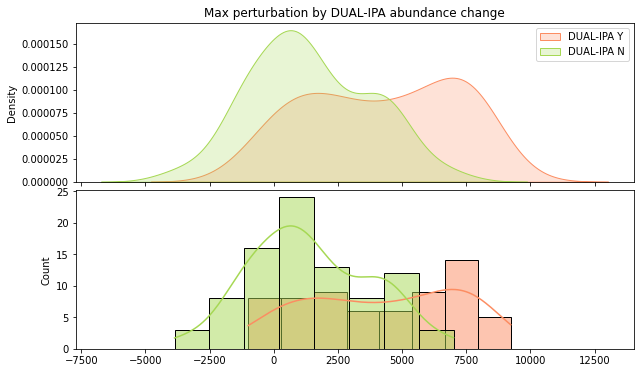

In [28]:

path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["max_perturbation"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["max_perturbation"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["max_perturbation"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["max_perturbation"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("Max perturbation by DUAL-IPA abundance change")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

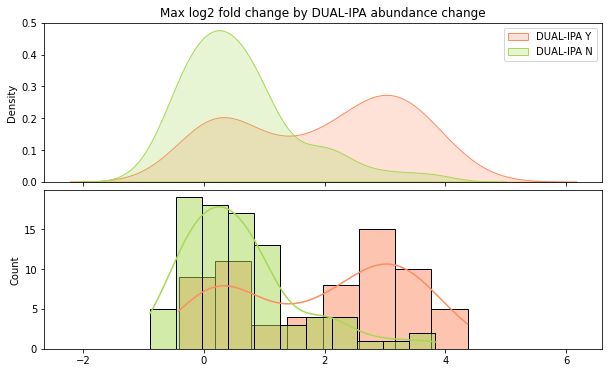

In [ ]:

path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["max_log2_fold_change"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["max_log2_fold_change"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["max_log2_fold_change"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["max_log2_fold_change"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
axes[0].set_title("Max log2 fold change by DUAL-IPA abundance change")
# axes[1].set_title("Histogram of max log2 fold change by DUAL-IPA abundance change")
plt.show()

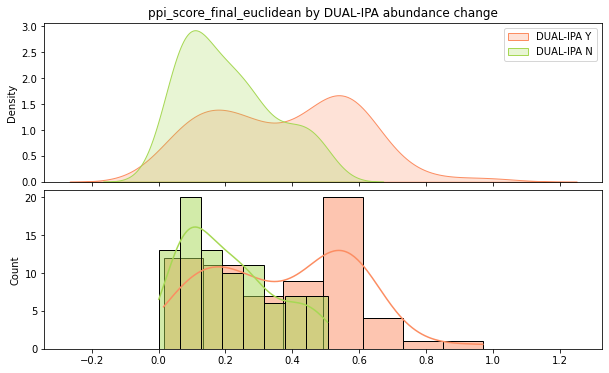

In [27]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["ppi_score_final_euclidean"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["ppi_score_final_euclidean"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="Y")["ppi_score_final_euclidean"].to_numpy(), label='DUAL-IPA Y', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(all_variants_df_ppi_pl.filter(pl.col("dualipa_abun_change")=="N")["ppi_score_final_euclidean"].to_numpy(), label='DUAL-IPA N', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].set_title("ppi_score_final_euclidean by DUAL-IPA abundance change")
plt.subplots_adjust(hspace=.05)
plt.show()

In [30]:
all_variants_df_ppi_pl

symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,StarStatus,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change
str,str,str,str,i64,f64,str,str,str,f64,f64,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,f64,bool,f64,bool,f64,f64,f64,f64,f64
"""LITAF""","""LITAF_Gly112Ser""","""ENSG00000189067""","""NC_000016.10:11553576:C:T""",52920,2677.0,"""334G>A""","""Gly112Ser""","""1_Pathogenic""",6.8406e-7,2.0,""".""","""0.81648""",""".""","""-10.652""","""0.77788""","""D""",87.33,0.083333,"""<10""","""70-90""",null,null,null,0.899325,false,0.223933,false,1.784181,2457.776872,2457.776872,1.784181,0.835262
"""THAP1""","""THAP1_Gly9Cys""","""ENSG00000131931""","""NC_000008.11:42843070:C:A""",1668,214082.0,"""25G>T""","""Gly9Cys""","""1_Pathogenic""",null,null,"""0.8901""","""0.82057""","""P""","""-8.673""","""0.65646""","""D""",80.91,0.8214286,"""10-90""","""70-90""",null,null,null,0.728205,false,0.181243,false,0.954075,-349.390844,349.390844,0.954075,-0.067825
"""GALE""","""GALE_Arg239Trp""","""ENSG00000117308""","""NC_000001.11:23796777:G:A""",2767,214360.0,"""715C>T""","""Arg239Trp""","""1_Pathogenic""",0.000008,2.0,"""0.8417""","""0.79282""","""P""","""-13.749""","""0.92228""","""D""",98.64,0.112903,"""10-90""",""">90""",0.113185,"""N""","""Increase""",0.787624,false,0.106609,false,0.797119,-1014.717656,1014.717656,0.797119,-0.327133
"""PCCA""","""PCCA_Ile450Val""","""ENSG00000175198""","""NC_000013.11:100309902:A:G""",888,200364.0,"""1348A>G""","""Ile450Val""","""2_Benign""",0.0477926,2.0,"""0.1911""","""0.41051""","""B""","""-4.115""","""0.28708""","""T""",97.66,0.017751,"""<10""",""">90""",null,null,null,null,null,0.373866,false,1.740297,3558.513862,3558.513862,1.740297,0.799334
"""IER3IP1""","""IER3IP1_Val21Gly""","""ENSG00000134049""","""NC_000018.10:47176216:A:C""",6408,215945.0,"""62T>G""","""Val21Gly""","""4_VUS""",0.000003,2.0,"""0.9594""","""0.87954""","""P""","""-12.046""","""0.85115""","""D""",60.82,0.28169,"""10-90""","""50-70""",null,null,null,null,null,0.25164,false,2.534152,3021.938655,3021.938655,2.534152,1.341503
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""KRT6A""","""KRT6A_Glu472Lys""","""ENSG00000205420""","""NC_000012.12:52488338:C:T""",4870,215286.0,"""1414G>A""","""Glu472Lys""","""1_Pathogenic""",null,2.0,"""0.9574""","""0.87713""","""P""","""-15.472""","""0.96867""","""D""",66.46,0.520619,"""10-90""","""50-70""",0.282414,"""N""","""Increase""",0.836835,false,0.199536,false,1.4609,2282.988308,2282.988308,1.4609,0.546857
"""TPM1""","""TPM1_Asp175Asn""","""ENSG00000140416""","""NC_000015.10:63060899:G:A""",4723,8952.0,"""523G>A""","""Asp175Asn""","""1_Pathogenic""",0.000007,2.0,"""0.5117""","""0.70216""","""A""","""-11.418""","""0.81957""","""D""",98.37,0.5153374,"""10-90""",""">90""",0.964807,"""Uncertain""","""Increase""",null,null,0.242798,false,1.076935,620.684955,620.684955,1.076935,0.106931
"""SMAD3""","""SMAD3_Met255Arg""","""ENSG00000166949""","""NC_000015.10:67181346:T:G""",11805,2144.0,"""764T>G""","""Met255Arg""","""4_VUS""",null,1.0,"""0.9918""","""0.95051""","""P""","""-12.394""","""0.86751""","""D""",95.32,0.010638,"""<10""",""">90""",-5.913824,"""Y""","""Decrease""",0.953229,true,0.407091,false,6.867155,4694.360995,4694.360995,6.867155,2.779713


In [ ]:
def plot_assay_hit_by_category(df, hit_col, cat_cols, title="", ax=None):
    """
    plot_assay_hit_by_category
    ==========================
    
    Create a paired horizontal bar chart that shows, for every category in
    `cat_cols`, both the **total number of observations** and the **number of
    positive hits** (as defined by `hit_col`).  The chart also annotates the
    hit-rate as a percentage.
    
    Parameters
    ----------
    df : polars.DataFrame
        Input table containing at least the columns listed in `cat_cols` and a
        boolean column indicating hits.
    hit_col : str
        Name of the boolean column that flags hits (e.g. `"is_hit"`).
    cat_cols : str or list[str]
        Column(s) that define the categorical grouping(s).  If a single string is
        supplied it is handled automatically.
    title : str, optional
        Title placed above the plot.
    ax : matplotlib.axes.Axes, optional
        Pre-existing axes to draw on.  If None, a new figure and axes are created.
    
    Returns
    -------
    polars.DataFrame
        A tidy frame with one row per category, containing:
            - the grouping key(s)
            - total_counts   : total observations in that category
            - hit_counts     : observations that were hits
            - hit_perc       : hit rate in percent (hit_counts / total_counts * 100)
    
    Example
    -------
    >>> plot_assay_hit_by_category(
    ...     df=my_data,
    ...     hit_col="is_hit",
    ...     cat_cols="clinvar_clnsig_clean",
    ...     title="Hit rate by ClinVar significance"
    ... )
    """
    # --- compute hit counts and percentages ---
    df_tot_cnt_per_cat = (
        df.group_by(cat_cols)
        .len()
        .rename({"len": "total_counts"})
    )
    df_hit_cnt_per_cat = (
        df.unique("gene_variant")
        .filter(pl.col(hit_col))
        .group_by(cat_cols)
        .len()
        .rename({"len": "hit_counts"})
    )

    img_hits_perc_df = (
        df_tot_cnt_per_cat.join(
            df_hit_cnt_per_cat,
            on=cat_cols,
            how="left"
        )
        .fill_null(0)
        .with_columns(
            (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
        )
        .sort(cat_cols)
    )

    # --- plotting ---
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(6, img_hits_perc_df.shape[0]))

    plot_df = img_hits_perc_df.to_pandas()

    # total bars (blue)
    sns.barplot(
        data=plot_df,
        y=cat_cols if isinstance(cat_cols, str) else cat_cols[-1],
        x="total_counts",
        color="steelblue",
        label="Total count",
        ax=ax
    )

    # hit bars (red)
    sns.barplot(
        data=plot_df,
        y=cat_cols if isinstance(cat_cols, str) else cat_cols[-1],
        x="hit_counts",
        color="tomato",
        label="Hit count",
        ax=ax
    )

    ax.set_title(title)
    ax.grid(alpha=.2)

    # percentage annotations
    max_tot = plot_df["total_counts"].max()
    for idx, row in plot_df.iterrows():
        ax.text(
            row["hit_counts"] + max_tot * 0.01,
            idx,
            f"{row['hit_perc']:.1f}%",
            va="center",
            ha="left",
            fontweight="bold",
            fontsize=12,
            color="black"
        )

    return img_hits_perc_df

pLDDT_Category,total_counts,hit_counts,hit_perc
cat,u32,u32,f64
"""<=50""",28,1,3.571429
"""50-70""",32,1,3.125
"""70-90""",70,4,5.714286
""">90""",334,52,15.568862


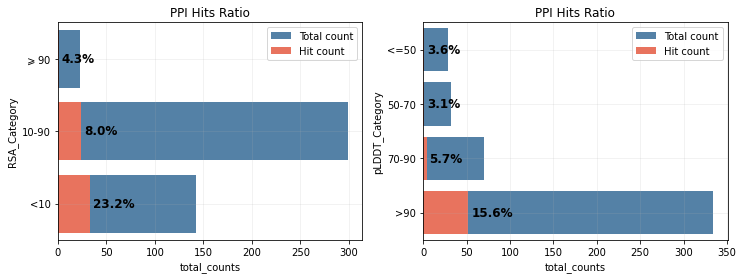

In [36]:
# Set the proper order for pLDDT categories
plddt_order = ["<=50", "50-70", "70-90", ">90"]

# First convert to pandas to set the categorical order, then back to polars
all_variants_df_ppi_pd = all_variants_df_ppi_pl.to_pandas()
all_variants_df_ppi_pd['pLDDT_Category'] = pd.Categorical(
    all_variants_df_ppi_pd['pLDDT_Category'], 
    categories=plddt_order, 
    ordered=True
)
all_variants_df_ppi_pl = pl.from_pandas(all_variants_df_ppi_pd)

fig, axes = plt.subplots(1,2,figsize=(12,4))
plot_assay_hit_by_category(all_variants_df_ppi_pl, "ppi_hit", "RSA_Category", f"PPI Hits Ratio", ax=axes[0])
plot_assay_hit_by_category(all_variants_df_ppi_pl, "ppi_hit", "pLDDT_Category", f"PPI Hits Ratio", ax=axes[1])

In [38]:
all_variants_df_ppi_pl

symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,StarStatus,AlphaMissense_score,AlphaMissense_rankscore,AlphaMissense_pred,ESM1b_score,ESM1b_rankscore,ESM1b_pred,plddt_f32,rsa_f32,RSA_Category,pLDDT_Category,dualipa_abun_score,dualipa_abun_change,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change
str,str,str,str,i64,f64,str,str,str,f64,f64,str,str,str,str,str,str,f64,f64,str,cat,f64,str,str,f64,bool,f64,bool,f64,f64,f64,f64,f64
"""LITAF""","""LITAF_Gly112Ser""","""ENSG00000189067""","""NC_000016.10:11553576:C:T""",52920,2677.0,"""334G>A""","""Gly112Ser""","""1_Pathogenic""",6.8406e-7,2.0,""".""","""0.81648""",""".""","""-10.652""","""0.77788""","""D""",87.33,0.083333,"""<10""","""70-90""",null,null,null,0.899325,false,0.223933,false,1.784181,2457.776872,2457.776872,1.784181,0.835262
"""THAP1""","""THAP1_Gly9Cys""","""ENSG00000131931""","""NC_000008.11:42843070:C:A""",1668,214082.0,"""25G>T""","""Gly9Cys""","""1_Pathogenic""",null,null,"""0.8901""","""0.82057""","""P""","""-8.673""","""0.65646""","""D""",80.91,0.8214286,"""10-90""","""70-90""",null,null,null,0.728205,false,0.181243,false,0.954075,-349.390844,349.390844,0.954075,-0.067825
"""GALE""","""GALE_Arg239Trp""","""ENSG00000117308""","""NC_000001.11:23796777:G:A""",2767,214360.0,"""715C>T""","""Arg239Trp""","""1_Pathogenic""",0.000008,2.0,"""0.8417""","""0.79282""","""P""","""-13.749""","""0.92228""","""D""",98.64,0.112903,"""10-90""",""">90""",0.113185,"""N""","""Increase""",0.787624,false,0.106609,false,0.797119,-1014.717656,1014.717656,0.797119,-0.327133
"""PCCA""","""PCCA_Ile450Val""","""ENSG00000175198""","""NC_000013.11:100309902:A:G""",888,200364.0,"""1348A>G""","""Ile450Val""","""2_Benign""",0.0477926,2.0,"""0.1911""","""0.41051""","""B""","""-4.115""","""0.28708""","""T""",97.66,0.017751,"""<10""",""">90""",null,null,null,null,null,0.373866,false,1.740297,3558.513862,3558.513862,1.740297,0.799334
"""IER3IP1""","""IER3IP1_Val21Gly""","""ENSG00000134049""","""NC_000018.10:47176216:A:C""",6408,215945.0,"""62T>G""","""Val21Gly""","""4_VUS""",0.000003,2.0,"""0.9594""","""0.87954""","""P""","""-12.046""","""0.85115""","""D""",60.82,0.28169,"""10-90""","""50-70""",null,null,null,null,null,0.25164,false,2.534152,3021.938655,3021.938655,2.534152,1.341503
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""KRT6A""","""KRT6A_Glu472Lys""","""ENSG00000205420""","""NC_000012.12:52488338:C:T""",4870,215286.0,"""1414G>A""","""Glu472Lys""","""1_Pathogenic""",null,2.0,"""0.9574""","""0.87713""","""P""","""-15.472""","""0.96867""","""D""",66.46,0.520619,"""10-90""","""50-70""",0.282414,"""N""","""Increase""",0.836835,false,0.199536,false,1.4609,2282.988308,2282.988308,1.4609,0.546857
"""TPM1""","""TPM1_Asp175Asn""","""ENSG00000140416""","""NC_000015.10:63060899:G:A""",4723,8952.0,"""523G>A""","""Asp175Asn""","""1_Pathogenic""",0.000007,2.0,"""0.5117""","""0.70216""","""A""","""-11.418""","""0.81957""","""D""",98.37,0.5153374,"""10-90""",""">90""",0.964807,"""Uncertain""","""Increase""",null,null,0.242798,false,1.076935,620.684955,620.684955,1.076935,0.106931
"""SMAD3""","""SMAD3_Met255Arg""","""ENSG00000166949""","""NC_000015.10:67181346:T:G""",11805,2144.0,"""764T>G""","""Met255Arg""","""4_VUS""",null,1.0,"""0.9918""","""0.95051""","""P""","""-12.394""","""0.86751""","""D""",95.32,0.010638,"""<10""",""">90""",-5.913824,"""Y""","""Decrease""",0.953229,true,0.407091,false,6.867155,4694.360995,4694.360995,6.867155,2.779713


ColumnNotFoundError: "inheritance_pattern" not found

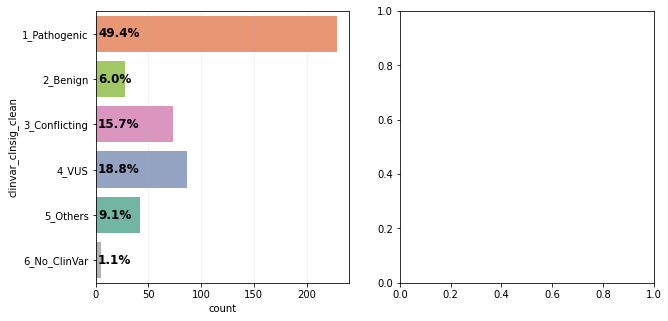

In [42]:

fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    all_variants_df_ppi_pl,
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)
plot_cat_count_perc(
    all_variants_df_ppi_pl,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)
plt.suptitle(f"{all_variants_df_ppi_pl.unique('gene_allele').shape[0]} Variants from {all_variants_df_ppi_pl.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

In [44]:
all_variants_df_ppi_pd

,symbol,gene_variant,ensembl_gene_id,spdi,orf_id,mut_id,nt_change,aa_change,clinvar_clnsig_clean,gnomad_af,...,dualipa_abun_chg_dir,AUROC_Mean_GFP,Altered_95th_perc_both_batches_GFP,ppi_score_final_euclidean,ppi_hit,max_perturbation_fold,max_perturbation,max_perturbation_abs,max_perturbation_fold_abs,max_log2_fold_change
0,LITAF,LITAF_Gly112Ser,ENSG00000189067,NC_000016.10:11553576:C:T,52920,2677.0,334G>A,Gly112Ser,1_Pathogenic,6.840600e-07,...,None,0.899325,False,0.223933,False,1.784181,2457.776872,2457.776872,1.784181,0.835262
1,THAP1,THAP1_Gly9Cys,ENSG00000131931,NC_000008.11:42843070:C:A,1668,214082.0,25G>T,Gly9Cys,1_Pathogenic,NaN,...,None,0.728205,False,0.181243,False,0.954075,-349.390844,349.390844,0.954075,-0.067825
2,GALE,GALE_Arg239Trp,ENSG00000117308,NC_000001.11:23796777:G:A,2767,214360.0,715C>T,Arg239Trp,1_Pathogenic,8.230060e-06,...,Increase,0.787624,False,0.106609,False,0.797119,-1014.717656,1014.717656,0.797119,-0.327133
3,PCCA,PCCA_Ile450Val,ENSG00000175198,NC_000013.11:100309902:A:G,888,200364.0,1348A>G,Ile450Val,2_Benign,4.779260e-02,...,None,NaN,None,0.373866,False,1.740297,3558.513862,3558.513862,1.740297,0.799334
4,IER3IP1,IER3IP1_Val21Gly,ENSG00000134049,NC_000018.10:47176216:A:C,6408,215945.0,62T>G,Val21Gly,4_VUS,2.749860e-06,...,None,NaN,None,0.251640,False,2.534152,3021.938655,3021.938655,2.534152,1.341503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
459,KRT6A,KRT6A_Glu472Lys,ENSG00000205420,NC_000012.12:52488338:C:T,4870,215286.0,1414G>A,Glu472Lys,1_Pathogenic,NaN,...,Increase,0.836835,False,0.199536,False,1.460900,2282.988308,2282.988308,1.460900,0.546857
460,TPM1,TPM1_Asp175Asn,ENSG00000140416,NC_000015.10:63060899:G:A,4723,8952.0,523G>A,Asp175Asn,1_Pathogenic,6.840680e-06,...,Increase,NaN,None,0.242798,False,1.076935,620.684955,620.684955,1.076935,0.106931
461,SMAD3,SMAD3_Met255Arg,ENSG00000166949,NC_000015.10:67181346:T:G,11805,2144.0,764T>G,Met255Arg,4_VUS,NaN,...,Decrease,0.953229,True,0.407091,False,6.867155,4694.360995,4694.360995,6.867155,2.779713
462,AGXT,AGXT_Pro319Leu,ENSG00000172482,NC_000002.12:240878035:C:T,70497,3878.0,956C>T,Pro319Leu,1_Pathogenic,NaN,...,Decrease,0.741186,False,0.436285,False,3.988370,4152.627593,4152.627593,3.988370,1.995799


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_57173/2179577097.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_57173/2179577097.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


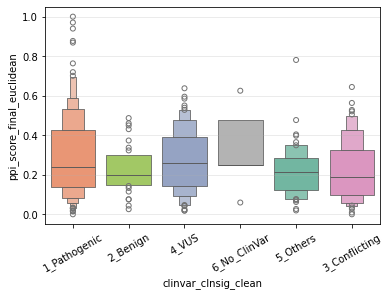

In [45]:
ax = sns.boxenplot(
    data=all_variants_df_ppi_pl.to_pandas(),
    x="clinvar_clnsig_clean",
    y="ppi_score_final_euclidean",
    # hue="inheritance_pattern",
    # hue_order=hue_order,
    palette=palette_dict["clinvar_clnsig_clean"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
plt.show()

In [46]:
scores

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,normalized_euclid_distance,normalized_mahalanobis_distance,ppi_score_final_euclidean,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,ppi_hit
f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64,bool
291.33589,291.33589,0.106659,291.33589,1.119393,1.119393,0.162716,0.162716,null,1,false,0.0,-291.33589,-0.106659,null,2440.145192,0.893341,291.33589,null,0.030608,"""TTR""","""Ile88Leu""","""262A>T""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",0.000011,2.0,"""TTR_Ile88Leu""",8999,202999,"""TTR""","""Ile88Leu""","""ENSG00000118271""","""1_Pathogenic""",0.000011,2.0,false
7433.634245,7433.634245,0.886822,7433.634245,8.835638,8.835638,3.143334,3.143334,null,1,true,1.0,-7433.634245,-0.886822,null,948.695439,0.113178,7433.634245,null,0.780995,"""NCF2""","""Gly44Arg""","""130G>C""","""ENSG00000116701""","""CEGS2""","""5_Others""",null,null,"""NCF2_Gly44Arg""",3727,214871,"""NCF2""","""Gly44Arg""","""ENSG00000116701""","""5_Others""",null,null,true
5237.574029,-5237.574029,-1.786488,5237.574029,0.358875,0.358875,-1.478448,1.478448,null,1,false,0.0,5237.574029,1.786488,null,8169.345313,2.786488,5237.574029,null,0.550272,"""GATA2""","""Cys373Arg""","""1117T>C""","""ENSG00000179348""","""CEGS2""","""1_Pathogenic""",null,2.0,"""GATA2_Cys373Arg""",7465,216383,"""GATA2""","""Cys373Arg""","""ENSG00000179348""","""1_Pathogenic""",null,2.0,true
3156.668069,3156.668069,0.743425,3156.668069,3.897492,3.897492,1.962546,1.962546,null,1,false,0.0,-3156.668069,-0.743425,null,1089.44838,0.256575,3156.668069,null,0.331647,"""AP2S1""","""Arg15His""","""44G>A""","""ENSG00000042753""","""CEGS2""","""1_Pathogenic""",null,2.0,"""AP2S1_Arg15His""",4983,215316,"""AP2S1""","""Arg15His""","""ENSG00000042753""","""1_Pathogenic""",0.000002,2.0,false
6964.535265,5036.682463,0.653152,5036.682463,2.883107,2.883107,1.527624,1.527624,null,3,false,0.0,-3901.095981,-0.529586,0.107624,2674.666759,0.346848,4020.97631,null,0.422453,"""KRT6A""","""Ile462Asn""","""1385T>A""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,2.0,"""KRT6A_Ile462Asn""",4870,215289,"""KRT6A""","""Ile462Asn""","""ENSG00000205420""","""1_Pathogenic""",null,2.0,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
7029.011714,4297.695528,0.469609,4297.695528,1.885402,1.885402,0.914872,0.914872,null,3,false,0.0,-615.917335,0.054825,0.772879,4853.946631,0.530391,4058.201805,null,0.426364,"""NMNAT1""","""Asn273Asp""","""817A>G""","""ENSG00000173614""","""CEGS2""","""1_Pathogenic""",6.8516e-7,null,"""NMNAT1_Asn273Asp""",7675,202587,"""NMNAT1""","""Asn273Asp""","""ENSG00000173614""","""1_Pathogenic""",6.8516e-7,null,false
2561.049763,2561.049763,0.30553,2561.049763,1.439946,1.439946,0.526015,0.526015,null,1,false,0.0,-2561.049763,-0.30553,null,5821.279922,0.69447,2561.049763,null,0.26907,"""NCF2""","""Asp108Val""","""323A>T""","""ENSG00000116701""","""CEGS2""","""4_VUS""",null,1.0,"""NCF2_Asp108Val""",3727,214873,"""NCF2""","""Asp108Val""","""ENSG00000116701""","""4_VUS""",null,1.0,false
9694.76342,6834.451679,0.877106,6834.451679,8.137079,8.137079,3.024511,3.024511,null,8,false,0.125,1271.054953,0.524213,0.652018,957.597856,0.122894,3427.616478,null,0.360114,"""KCTD7""","""Arg94Trp""","""280C>T""","""ENSG00000243335""","""CEGS2""","""1_Pathogenic""",0.000009,2.0,"""KCTD7_Arg94Trp""",70368,205542,"""KCTD7""","""Arg94Trp""","